# 3. Nearest neighbours, logistic regression and size of the illegal CSP sector

This notebook covers Sections 3.3 and 4 and Appendices A.7, A.9 and A.10 of the paper:

1. Nearest neighbours (Section 3.3.1, Figure 3) and robustness tests (Section 4.3, Appendices A.7 and A.9).
2. Samples for the manual annotation (Section 3.3.3) and their results.
3. Penalized logistic regression (Section 3.3.2, Appendix A.10).
4. Characteristics of the flagged directors (Section 4.2, Figure 6).
5. Size of the illegal CSP sector (Section 4.1, Figures 4 and 5).
6. Extrapolation to small CSPs (Section 4.3, Figure 7).

**Inputs**: outputs of notebooks 1 and 2, and the manually annotated samples (not included, they contain personal data). Figures are saved to `Figures/`.

Terminology: *RTO* = licensed CSP; `RTO_confidence`: 7, 6 and 4 = licensed CSPs (steps i, iia and iib in Section 3.1.2), 1 = other directors, 0 = directors not providing corporate services; `ix` = flagged by the nearest neighbours; `ix_logit` = flagged by the logistic regression.

In [1]:
RECOMPUTE = False                  # True: compute the t-SNE embedding again (it is always computed if it was not saved before)
CREATE_ANNOTATION_SAMPLES = False  # True: draw new random samples for the manual annotation

In [2]:
import os
import re
import json
import pickle
from ast import literal_eval
from collections import Counter

import numpy as np
import pandas as pd
import pylab as plt
import seaborn as sns
import matplotlib.ticker as mtick
import statsmodels.formula.api as smf
from scipy.stats import beta
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import roc_curve
from tqdm.notebook import tqdm
from IPython.display import display

%matplotlib inline
sns.set(font_scale=1.3)
sns.set_style("whitegrid")
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 150)
pd.set_option('display.width', 1000)
pd.options.mode.chained_assignment = None  # ignore SettingWithCopy warnings

In [3]:
def bootstrap_ci(data, statfunction=np.average, alpha=0.05, n_samples=100):
    """Bootstrap confidence interval (inspired by https://github.com/cgevans/scikits-bootstrap)."""
    import warnings

    def bootstrap_ids(data, n_samples=100):
        for _ in range(n_samples):
            yield np.random.randint(data.shape[0], size=(data.shape[0],))

    alphas = np.array([alpha/2, 1 - alpha/2])
    nvals = np.round((n_samples - 1) * alphas).astype(int)
    if np.any(nvals < 10) or np.any(nvals >= n_samples-10):
        warnings.warn("Some values used extremal samples; results are probably unstable. "
                      "Try to increase n_samples")

    data = np.array(data)
    if np.prod(data.shape) != max(data.shape):
        raise ValueError("Data must be 1D")
    data = data.ravel()

    boot_indexes = bootstrap_ids(data, n_samples)
    stat = np.asarray([statfunction(data[_ids]) for _ids in boot_indexes])
    stat.sort(axis=0)
    return stat[nvals]

In [4]:
# Description of the variables (Table 1 and Appendix A.4)
var2eng = {'corp': 'Is the director an individual or a corporate entity?',
           'corp_services': "Director's  name contains a corporate keyword",
           'dir_nace_check': 'Corporate director in a CSP-related sector',
           'n_dir_icij': 'Director appearing in offshore leaks',
           'same_directors': 'Corporate director: shared directors with companies',
           'mean_sim_dir_comps': 'Similarity names of company and director',
           'dir_freq': '% of companies with the title “director” (vs proxyholders, ceo, or others)',
           'top_title': '% of companies in which the director has the most frequent title',
           'dir_in_comp_nace_check': 'Any company in a CSP-related sector',
           'log_n_comp': 'Log number of companies',
           'av_companies_guo': ' Number of companies per GUO',
           'number_shared_directors': 'Number of shared directors between the companies',
           'mean_sim': 'String similarity between company names',
           'nace_finance': '% of companies in finance',
           'nace_holding': '% of holding companies (NACE 6420)',
           'nace_real_estate': '% of real estate companies',
           'nace_top_holding': '% of top holdings',
           'nace_adminis': '% of administrative companies',
           'nace_unknown': '% of companies with unknown sector',
           'nace_retail_wholesale': '% of companies in retail/wholesale',
           'nace_construction': '% of companies in construction',
           'top_nace': '% of companies of top sector',
           'legal_bv': '% of BVs',
           'legal_found': '% of Foundations',
           'legal_vof': '% of VOFs',
           'legal_coop': '% of Cooperatives',
           'legal_cv': '% of CVs',
           'top_legal': '% of companies with the top legal form',
           'frac_dir_prev_rto4': '% of companies with a previous licensed CSP',
           'av_n_prev_add': 'Average number of previous address',
           'av_n_prev_dir': 'Average number of previous directors',
           'frac_comp_icij': 'Number of companies in offshore leaks',
           'log_total_guo': 'Log number of independent companies',
           'av_directors_comps': 'Average number of directors per independent company',
           'office_top': '% of companies in the top office address',
           'postal_top': '% of companies in the top postal address',
           'log_n_comps_top_office': 'Log # of companies in the top office address',
           'log_n_comps_top_postal': 'Log # of companies in the top postal address',
           'frac_add_prev_trust': '% of companies previously in an address of CSP (augmented)',
           'frac_add_prev_trust_off': '% of companies previously in an address of CSP',
           'frac_add_off_icij': 'Number of office addresses in offshore leaks',
           'frac_add_post_icij': 'Number of postal addresses in offshore leaks',
           'same_guo': 'Number of directors acting as owners.',
           'same_guo_frac': '% of directors acting as owners. ',
           'no_guo': '% of companies with unknown owner',
           'nl_guo': '% of companies with domestic owner',
           'foreign_guo': '% of companies with foreign owner',
           'ofc_guo': '% of companies with owner in an OFC'}

## 0. Read the data

In [5]:
df_c = pd.read_csv("data_final/df_company_info.tsv", sep="\t", converters={"nace": str})
df_c["nace"] = df_c["nace"].str.zfill(4).replace("0000", np.nan)
df_c = df_c.rename(columns={"index": "bvd_id"})
bvd2nace = df_c.set_index("bvd_id")["nace"].to_dict()
bvd2name = df_c.set_index("bvd_id")["company_name"].to_dict()
bvd_to_legal = df_c.set_index("bvd_id")["legal_form"].to_dict()

# CSP-related sectors: 82.11 Combined office administrative service activities; 66.19 Other activities auxiliary to financial
# services; 69.20 Accounting, bookkeeping and auditing, tax consultancy; 70.22 Business and other management consultancy;
# 64.30 Trusts, funds and similar financial entities
sector_bvd = set(df_c.loc[df_c["nace"].isin(["8211", "6619", "6920", "7022", "6430"]), "bvd_id"].unique())
sector_comp = set(df_c.loc[df_c["nace"].isin(["8211", "6619", "6920", "7022", "6430"]), "company_name"].unique())

In [6]:
df_cluster = pd.read_csv("data_processing/directors_clustering_extra_info.tsv", sep="\t")
# Number of directors in each group (RTO_confidence) and licensed CSPs from the DNB list (RTO)
pd.crosstab(df_cluster["RTO"], df_cluster["RTO_confidence"])

RTO_confidence,0,1,4,6,7
RTO,,,,,
False,1551,34083,261,493,0
True,0,0,0,0,155


In [7]:
# Directors with over 40% of their companies in a CSP-related sector
df_dir_current = pd.read_csv("data_final/layers/df_dir_current.csv", sep="\t")
df_dir_current["s"] = df_dir_current["bvd_id"].isin(sector_bvd)
df_dir_current = df_dir_current.loc[df_dir_current["dir_id"].isin(set(df_cluster["dir_id"]))]
x = df_dir_current.groupby("dir_id").agg({"bvd_id": len, "s": "sum"})
x["rat"] = x["s"]/x['bvd_id']
dirs_of_sector = set(x.loc[x["rat"] > 0.4].index)

df_cluster["dir_nace_check"] = df_cluster["dir_bvd_id"].isin(sector_bvd) | df_cluster["dir_name"].isin(sector_comp)
df_cluster["dir_in_comp_nace_check"] = df_cluster["dir_id"].isin(dirs_of_sector)

names_check = "|".join(["FINANCIAL", "TAX", "MANAGEMENT", "TRUST", "CORPORATE", "CONSULTANT", "ADVIES", "ADVISORS", "MANAGERS", "SERVICES", "FIDUCIA", "ADMINISTRATION"])
df_cluster["corp_services"] = df_cluster["dir_name"].str.contains(names_check)

df_cluster["RTO_conf_bool"] = df_cluster["RTO_confidence"] >= 4  # licensed CSP

In [8]:
# Features used in the nearest neighbours algorithm
vars_fit = ['dir_nace_check', 'dir_in_comp_nace_check', 'corp_services', 'corp', 'log_total_guo', 'log_n_comp', 'av_directors_comps', 'number_shared_directors',
            'office_top', 'log_n_comps_top_office',
            'postal_top', 'log_n_comps_top_postal',
            'nace_finance', 'nace_holding', 'nace_real_estate', 'nace_top_holding', 'nace_adminis',
            'nace_unknown', 'nace_retail_wholesale', 'nace_construction', 'top_nace',
            'dir_freq', 'top_title', 'legal_bv', 'legal_found', 'legal_vof', 'legal_coop', 'legal_cv', 'top_legal',
            'no_guo', 'nl_guo', 'foreign_guo', 'ofc_guo', 'mean_sim',
            'same_directors', 'av_companies_guo',
            'frac_add_prev_trust', 'frac_add_prev_trust_off',
            'frac_dir_prev_rto7', 'frac_dir_prev_rto6',
            'frac_dir_prev_rto4',
            'same_guo', 'same_guo_frac', 'mean_sim_dir_comps', 'av_n_prev_add', 'av_n_prev_dir', 'n_dir_icij',
            'frac_add_off_icij', 'frac_add_post_icij', 'frac_comp_icij']

## 1. Nearest neighbours (Section 3.3.1)

For each seed (licensed CSPs and corporate directors in a CSP-related sector with the typical profile of a CSP), find the 100 closest directors in the standardized feature space. Directors that are among the neighbours of more than `min_x` seeds are flagged, with `min_x` chosen to keep approximately `top_n` directors in addition to the licensed CSPs.

In [9]:
def create_neighbors(df_cluster, vars_fit, cond2_create=True, top_n=3000, print_stats=True, rto_confidence=4):
    """Adds the columns i (position), ix (flagged) and ix_count (number of seeds with the director among their 100 neighbours)."""
    X = df_cluster[vars_fit].values
    X = StandardScaler().fit_transform(X)

    neigh = NearestNeighbors()
    neigh.fit(X)

    cond2 = ((df_cluster["dir_nace_check"]) & (df_cluster["same_guo"] == 0) & (df_cluster["foreign_guo"] > 0)
             & (df_cluster["mean_sim_dir_comps"] < 0.2) & (df_cluster["nace_finance"] > 0.2)) & (df_cluster["av_directors_comps"] < 3)
    cond1 = (df_cluster["RTO_confidence"] >= rto_confidence)
    if print_stats:
        print(cond1.sum(), cond2.sum())
    if cond2_create:
        nbrs = neigh.kneighbors(X[cond1 | cond2, :], 100, return_distance=False)
    else:
        nbrs = neigh.kneighbors(X[cond1, :], 100, return_distance=False)

    # Keep the top_n directors (plus the licensed CSPs)
    top_n = top_n + (df_cluster["RTO_confidence"] >= 4).sum()
    c = Counter(np.concatenate(nbrs))
    min_x = c.most_common(top_n)[-1][-1]
    nbrs2 = set([_[0] for _ in c.most_common(top_n) if _[1] > min_x])
    if print_stats:
        print(len(c), "min", min_x, len(nbrs2))

    df_cluster["i"] = range(len(df_cluster))
    df_cluster["ix"] = df_cluster["i"].isin(nbrs2)
    df_cluster["ix_count"] = df_cluster["i"].map(c)

    if print_stats:
        df_cluster["topRTO"] = df_cluster["RTO_confidence"] == 7
        display(pd.crosstab([df_cluster["ix"], df_cluster["topRTO"]], df_cluster["RTO_confidence"] >= 4, margins=True))
        display(pd.crosstab(df_cluster["ix"], df_cluster["RTO_confidence"] >= 4, margins=True))

    return df_cluster

In [10]:
df_cluster = create_neighbors(df_cluster, vars_fit, top_n=3000)

909 68
8782 min 2 3830


RTO_confidence  False  True    All
ix    topRTO                      
False False     32690    21  32711
      True          0     2      2
True  False      2944   733   3677
      True          0   153    153
All             35634   909  36543

RTO_confidence,False,True,All
ix,,,
False,32690,23,32713
True,2944,886,3830
All,35634,909,36543


In [11]:
# 2D projection of the feature space (t-SNE)
if RECOMPUTE or not os.path.exists("data_processing/tsne_embedding.txt"):
    X = StandardScaler().fit_transform(df_cluster[vars_fit].values)
    X_embedded = TSNE(n_components=2, n_jobs=-1, init="pca").fit_transform(X)
    np.savetxt('data_processing/tsne_embedding.txt', X_embedded)
else:
    X_embedded = np.loadtxt('data_processing/tsne_embedding.txt')

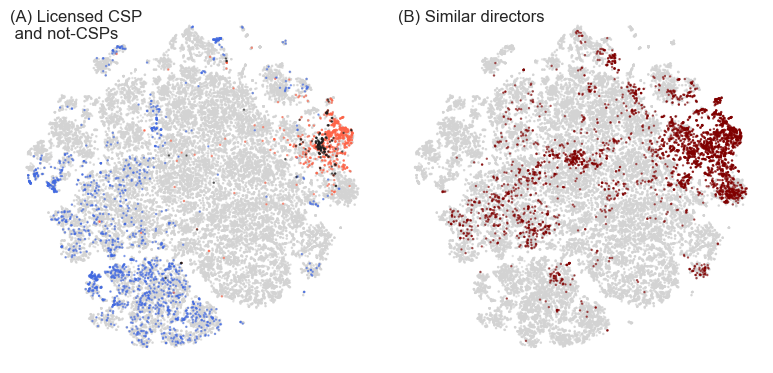

In [12]:
# Figure 3
plt.figure(figsize=(8, 4))
plt.subplot(122)
cs = ["lightgray", "maroon"]
color = np.array([cs[_] for _ in df_cluster["ix"]])
s = np.array([0.5]*len(color))
for filter_ in [color == "lightgray", color != "lightgray"]:
    plt.scatter(X_embedded[filter_, 0], X_embedded[filter_, 1], color=color[filter_], s=s[filter_], alpha=0.6)
plt.axis(False)
plt.annotate("(B) Similar directors", (0, 1), xycoords="axes fraction", fontsize=12, ha="left", va="top")

plt.subplot(121)
colors = ["royalblue", "lightgray"]+["tomato"]*5 + ["k"]  # by RTO_confidence (0 to 7)
color = np.array([colors[_] for _ in df_cluster["RTO_confidence"]])
for c_ in ["lightgray", "royalblue", "tomato", "k"]:
    filter_ = color == c_
    plt.scatter(X_embedded[filter_, 0], X_embedded[filter_, 1], color=color[filter_], s=s[filter_], alpha=0.6)
plt.axis(False)
plt.annotate("(A) Licensed CSP \n and not-CSPs", (0, 1), xycoords="axes fraction", fontsize=12, ha="left", va="top")
plt.tight_layout()
plt.savefig("Figures/nearest.pdf", bbox_inches="tight")

### Robustness tests

Without the licensed CSPs of step iib (Section 3.1.2): share of the directors flagged by the baseline that are still flagged.

In [13]:
df_cluster_6 = create_neighbors(df_cluster.copy(), vars_fit, print_stats=False, rto_confidence=6, top_n=3000)
display(pd.crosstab([df_cluster["RTO_confidence"] >= 4, df_cluster["ix"]], df_cluster_6["ix"]))
print((df_cluster["ix"] & df_cluster_6["ix"]).sum() / df_cluster["ix"].sum())

ix                    False  True 
RTO_confidence ix                 
False          False  32127    563
               True     522   2422
True           False     19      4
               True      31    855

0.8556135770234987


Feature selection (Appendix A.7): 100 runs using a random 80% of the variables.

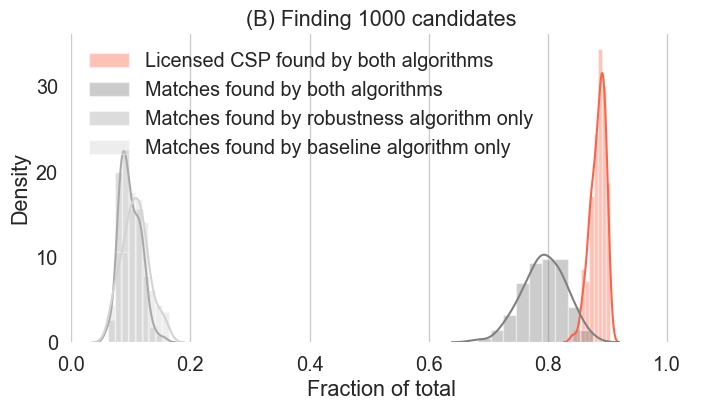

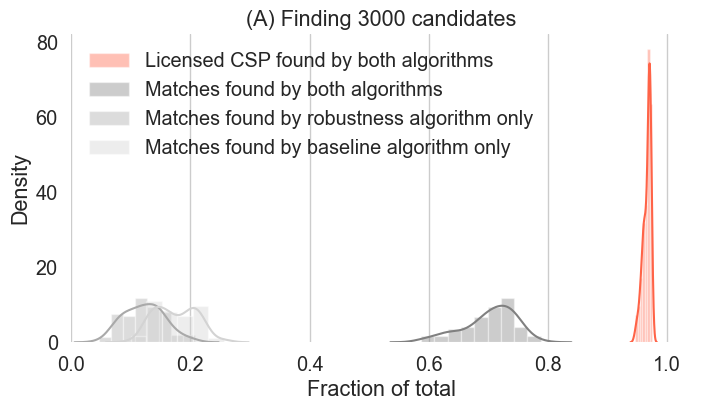

In [14]:
def robustness_vars(df_cluster, vars_fit, top_n=3000, letter=""):
    df_cluster = create_neighbors(df_cluster, vars_fit, top_n=top_n, print_stats=False)
    df_cluster["ix_real"] = df_cluster["ix"].copy()

    all_frac_rtos_both, all_frac_both, all_frac_new, all_frac_base = [], [], [], []
    for i in range(100):
        v = vars_fit.copy()
        np.random.shuffle(v)

        df_cluster = create_neighbors(df_cluster, v[:int(0.8*len(v))], top_n=top_n, print_stats=False)
        frac_rtos_both = np.sum((df_cluster["RTO_confidence"] >= 4) & (df_cluster["ix"]) & (df_cluster["ix_real"]))/(df_cluster["RTO_confidence"] >= 4).sum()
        frac_both = (df_cluster["ix"] & df_cluster["ix_real"]).sum() / (df_cluster["ix"] | df_cluster["ix_real"]).sum()
        frac_new = (df_cluster["ix"] & ~df_cluster["ix_real"]).sum() / (df_cluster["ix"] | df_cluster["ix_real"]).sum()
        frac_base = (~df_cluster["ix"] & df_cluster["ix_real"]).sum() / (df_cluster["ix"] | df_cluster["ix_real"]).sum()

        all_frac_rtos_both.append(frac_rtos_both)
        all_frac_both.append(frac_both)
        all_frac_new.append(frac_new)
        all_frac_base.append(frac_base)

    plt.figure(figsize=(8, 4))
    sns.distplot(all_frac_rtos_both, label="Licensed CSP found by both algorithms", norm_hist=True, color="tomato")
    sns.distplot(all_frac_both, label="Matches found by both algorithms", norm_hist=True, color="gray")
    sns.distplot(all_frac_new, label="Matches found by robustness algorithm only", color="darkgray", norm_hist=True)
    sns.distplot(all_frac_base, label="Matches found by baseline algorithm only", color="lightgray", norm_hist=True)
    plt.legend(frameon=False)
    plt.xlim(0, 1.04)
    plt.gca().grid(axis="y")
    plt.xlabel("Fraction of total")
    sns.despine(left=True, bottom=True)
    plt.title(f"{letter} Finding {top_n} candidates")
    plt.savefig(f"Figures/robust_vars_{top_n}.pdf", bbox_inches="tight")

robustness_vars(df_cluster.copy(), vars_fit, top_n=1000, letter="(B)")
robustness_vars(df_cluster.copy(), vars_fit, top_n=3000, letter="(A)")

False negatives (licensed CSPs not flagged) as a function of the number of directors kept (Appendix A.9).

In [15]:
# Number of seeds with each director among their 100 neighbours (baseline run)
nn_counts = Counter({i: n for i, n in zip(df_cluster["i"], df_cluster["ix_count"]) if n > 0})

top_ns = np.linspace(2, 20000, 501)
false_negs = []
check_comps = []
for top_n in tqdm(top_ns):
    top_n = int(top_n)
    min_x = nn_counts.most_common(top_n)[-1][-1]
    nbrs2 = set([_[0] for _ in nn_counts.most_common(top_n) if _[1] > min_x])

    cont = pd.crosstab(df_cluster["i"].isin(nbrs2), df_cluster["RTO_conf_bool"], margins=True)
    false_negs.append(cont.loc[False, True]/cont.loc["All", True])
    check_comps.append(cont.loc[True, False])

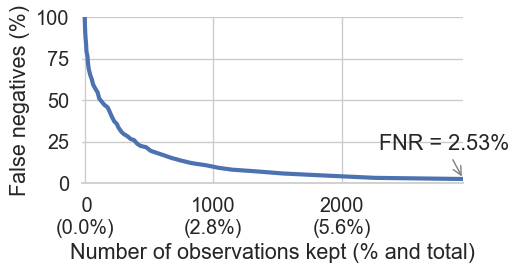

In [16]:
k = np.nonzero(top_ns > df_cluster["ix"].sum())[0][0]  # number of directors flagged by the nearest neighbours
n_not_licensed = (~df_cluster["RTO_conf_bool"]).sum()
x_max = check_comps[k]

plt.figure(figsize=(5, 3))
plt.plot(check_comps, 100*np.array(false_negs), lw=3)
plt.xlabel("Number of observations kept (% and total)")
plt.ylabel("False negatives (%)")
sns.despine(bottom=False, left=True)
plt.xlim(-20, x_max)
plt.ylim(0, 100)
plt.xticks(np.arange(0, x_max, 1000),
           ["{:2.0f}\n({:.1%})".format(_, _/n_not_licensed) for _ in np.arange(0, x_max, 1000)])
plt.tight_layout()
plt.annotate(f"FNR = {false_negs[k]:2.2%}", (x_max, 100*false_negs[k]), ha="center",
             xytext=(0.95*x_max, 20), arrowprops=dict(arrowstyle="->", color="gray"))
plt.savefig("Figures/app_roc.pdf", bbox_inches="tight")
plt.show()

## 2. Manual annotation (Section 3.3.3)

We annotated a random sample of 100 directors flagged by the nearest neighbours, and two random samples of 50 directors flagged by the logistic regression (Section 3 below) but not by the nearest neighbours.

`save_sample()` creates the spreadsheet for the annotators: a row with the director followed by one row for each company they manage (addresses, sector, legal form, owner, licensed CSPs at the same address, offshore leaks...). The annotators added the columns `Works for or is registerd trust operator?`, `Comment RTO `, `Provides trust services?` (1–5 scale, codebook in Appendix A.5), `Comment trust services` and `Completed` (1 when finished), and saved the files as `data_processing/annotated_sample_*.xlsx`.

The labels were checked by two of the authors. `annotated_sample_nn_raw.xlsx` is the nearest neighbours spreadsheet before coding the labels as numbers.

**The annotated samples are not included** (they contain personal data). Sections 3 and 5 need them.

In [17]:
# Offshore leaks (to flag them in the annotation spreadsheet)
icij_adds = pickle.load(open("data_final/icij_addresses.dump", "rb+"))
icij_ents = pickle.load(open("data_final/icij_entities.dump", "rb+"))
icij_offs = pickle.load(open("data_final/icij_officers.dump", "rb+"))
icij_ints = pickle.load(open("data_final/icij_intermediaries.dump", "rb+"))

icij_adds = ":::".join([_ for _ in icij_adds if isinstance(_, str)]).upper()
icij_ents = ":::".join([_ for _ in icij_ents if isinstance(_, str)]).upper()
icij_offs = ":::".join([_ for _ in icij_offs if isinstance(_, str)]).upper()
icij_ints = ":::".join([_ for _ in icij_ints if isinstance(_, str)]).upper()

remove_titles = set(['MR', 'MS', 'DRS.', 'IR.', 'DR.', 'DR', 'PROF.', 'ING.', 'MD', 'DRS', 'BARON', 'ING', 'GRAAF', 'MAG.', 'PROFESSOR', 'DIPL.-KFM.', 'IR', 'DIPL.-ING.'])

def query_icij(q, which="dir"):
    """Number of times a postcode (which="add"), a director name ("dir") or a company name (other) appears in the offshore leaks."""
    if q is None:
        return 0
    if which == "add":
        q = q.split("|")[0].strip()
        if len(q) != 6:
            return 0
        else:
            return len([1 for _ in re.finditer(q, icij_adds)])
    elif which == "dir":
        if q.split()[0] in remove_titles:
            q = " ".join(q.split()[1:])
    q = re.escape(q)
    return len([1 for _ in re.finditer(q, icij_ents)]) +\
        len([1 for _ in re.finditer(q, icij_offs)]) +\
        len([1 for _ in re.finditer(q, icij_ints)])

In [18]:
dir_2_bvd = df_dir_current.dropna(subset=["dir_bvd_id"]).set_index("dir_id")["dir_bvd_id"].to_dict()
dir_to_all_bvs = df_dir_current.groupby("dir_id")["bvd_id"].apply(list).to_dict()
bvd2dir = df_dir_current.groupby(["bvd_id"])["dir_id"].agg(list).to_dict()
bvd2guo = json.load(open("data_final/bvd2guo.json"))

df_comp_office_current = pd.read_csv("data_final/layers/df_comp_office_current.csv", sep="\t", index_col=0)
df_comp_postal_current = pd.read_csv("data_final/layers/df_comp_postal_current.csv", sep="\t", index_col=0)
df_comp_postbus_current = pd.read_csv("data_final/layers/df_comp_postbus_current.csv", sep="\t", index_col=0)

bvd2add = df_comp_office_current.set_index("bvd_id")["address_combined_gr"].to_dict()
bvd2add_postal = df_comp_postal_current.set_index("bvd_id")["address_combined_gr"].to_dict()
bvd2add_po = df_comp_postbus_current.set_index("bvd_id")["address_postbus"].to_dict()
bvd2add_full = df_comp_office_current.set_index("bvd_id")["address_full_norm"].to_dict()
bvd2add_postal_full = df_comp_postal_current.set_index("bvd_id")["address_full_norm"].to_dict()

add_to_countoffice = df_comp_office_current.groupby("address_combined_gr")["guo_id"].agg("nunique").to_dict()
add_to_countpostal = df_comp_postal_current.groupby("address_combined_gr")["guo_id"].agg("nunique").to_dict()

# Registered investment firms (AFM register)
investment_funds = pd.read_csv("data_raw_other/beleggingsondernemingen.csv", sep=";", encoding="latin1")
investment_funds = set(investment_funds["Statutaire naam"].str.upper()) | set(investment_funds["Handelsnaam"].str.upper())

# Companies (and previous positions/addresses) linked to each type of licensed CSP
bvd_2_flag_rto = json.load(open("data_processing/bvd_2_flag_rto.json"))
bvd2prev_dir_rto7 = pickle.load(open("data_final/bvd2prev_dir_rto7.pkl", "rb+"))
bvd2prev_dir_rto6 = pickle.load(open("data_final/bvd2prev_dir_rto6.pkl", "rb+"))
bvd2prev_dir_rto4 = pickle.load(open("data_final/bvd2prev_dir_rto4.pkl", "rb+"))
before_in_trust = pickle.load(open("data_final/before_in_trust.pkl", "rb+"))
before_in_trust_off = pickle.load(open("data_final/before_in_trust_off.pkl", "rb+"))

# Share of companies in each address managed by each type of licensed CSP
def share_rto(df):
    for col in ["dir_id_RTO7", "dir_id_RTO6", "dir_id_RTO4"]:
        df[col] = df["bvd_id"].map(bvd_2_flag_rto[col]) > 0
    df["c"] = 1
    ratios = df.groupby(["address_combined_gr"]).sum(numeric_only=True)
    for col in ["dir_id_RTO7", "dir_id_RTO6", "dir_id_RTO4"]:
        ratios[col] /= ratios["c"]
    return ratios.to_dict()

add_to_n_rtos = share_rto(df_comp_office_current)
add_postal_to_n_rtos = share_rto(df_comp_postal_current)
for col in ["dir_id_RTO7", "dir_id_RTO6", "dir_id_RTO4"]:
    add_postal_to_n_rtos[col][""] = np.nan

In [19]:
def save_sample(filename, sample):
    """Save the spreadsheet for the manual annotation of the directors in sample."""
    with open(f"data_processing/{filename}.csv", "w+") as f:
        for i, row in sample.iterrows():
            bvd_of_dir = dir_2_bvd.get(row["dir_id"])
            guo_of_dir = ""
            if (bvd_of_dir is not None) and (bvd2guo.get(bvd_of_dir) is not None):
                guo_of_dir = bvd2guo.get(bvd_of_dir)

            dir_in_icij = query_icij(row["dir_name"], which="dir")
            ids = "DIRECTOR\t{} ({}) (RTO {}) (GUO {}) (ICIJ {})\t\t\t\t\t\t\t\t\n".format(row["dir_name"], row["dir_id"], row["RTO_confidence"], guo_of_dir, dir_in_icij)
            f.write(ids)

            # Companies of the director, sorted by GUO
            companies_of_dir = dir_to_all_bvs[row["dir_id"]]
            guos_of_companies_of_dir = [bvd2guo.get(c) if bvd2guo.get(c) is not None else "ZZZ" for c in companies_of_dir]
            guos_of_companies_of_dir, companies_of_dir = zip(*sorted(zip(guos_of_companies_of_dir, companies_of_dir)))

            for i, c in enumerate(companies_of_dir):
                if bvd2add.get(c) is None:
                    print(c, ids)
                add = bvd2add[c]
                postal = bvd2add_postal.get(c) if bvd2add_postal.get(c) is not None else ""
                c_name = bvd2name[c]

                postal_full = bvd2add_postal_full.get(c) if bvd2add_postal_full.get(c) is not None else ""
                n_postal = add_to_countpostal[postal] if postal != "" else ""
                po = bvd2add_po.get(c) if bvd2add_po.get(c) is not None else ""
                guo = bvd2guo.get(c) if bvd2guo.get(c) is not None else ""
                dir_rto7 = bvd_2_flag_rto["dir_id_RTO7"][c]
                dir_rto6 = bvd_2_flag_rto["dir_id_RTO6"][c]
                dir_rto4 = bvd_2_flag_rto["dir_id_RTO4"][c]
                flag_r_if = bvd2name[c] in investment_funds

                add_in_icij = query_icij(add, which="add")
                postal_in_icij = query_icij(postal, which="add")
                comp_in_icij = query_icij(c_name, which="comp")

                f.write("Comp{}\t{}\t{}\t{}\t{} ({})\t{}\t{:2.1%}\t{:2.1%}\t{:2.1%}\t{} ({})\t{}\t{:2.1%}\t{:2.1%}\t{:2.1%}\t{}\t{}\t{}\t{}\t{}\t{}\t{}\t{}\t{}\t{}\t{}\t{}\t{}\t{}\t{}\t{}\t{}\n\n".format(i+1,
                        c_name, c, guo, bvd2add_full[c], add, add_to_countoffice[add], add_to_n_rtos["dir_id_RTO7"][add], add_to_n_rtos["dir_id_RTO6"][add], add_to_n_rtos["dir_id_RTO4"][add],
                        postal_full, postal, n_postal, add_postal_to_n_rtos["dir_id_RTO7"][postal], add_postal_to_n_rtos["dir_id_RTO6"][postal], add_postal_to_n_rtos["dir_id_RTO4"][postal], po, bvd2nace[c], bvd_to_legal[c],
                        guo[:2], len(bvd2dir[c]), dir_rto7, dir_rto6, dir_rto4, flag_r_if, c in bvd2prev_dir_rto7, c in bvd2prev_dir_rto6, c in bvd2prev_dir_rto4,
                        c in before_in_trust, c in before_in_trust_off, add_in_icij, postal_in_icij, comp_in_icij))

    data_manual = pd.read_csv(f"data_processing/{filename}.csv", sep="\t", header=None,
                              converters={"NACE sector": str},
                              names=["Type", "Company/Director Name", "Company ID", "Owner ID", "Office address", "N. companies in office address",
                                     "% RTO7 in office address", "% RTO6 in office address", "% RTO4 in office address", "Postal address", "N. companies in postal address",
                                     "% RTO7 in postal address", "% RTO6 in postal address", "% RTO4 in postal address", "Postbus", "NACE sector", "Legal form",
                                     "Country of owner", "# directors in company", "#RTO7 directors", "# RTO6 directors", "# RTO4 directors", "Registered investment fund", "Previous RTO7 director", "Previous RTO6 director", "Previous RTO4 director",
                                     "Previous RTO address (no branches)", "Previous RTO address (all branches)", "Office adddress in ICIJ", "Postal address in ICIJ", "Company in ICIJ"])
    data_manual.to_excel(f"data_processing/{filename}.xlsx", index=None)
    sample[["dir_id", "dir_name", "RTO", "RTO_confidence"]].to_excel(f"data_processing/code_{filename}.xlsx", index=None)

    return data_manual

In [20]:
# Random sample of 100 directors flagged by the nearest neighbours
if CREATE_ANNOTATION_SAMPLES:
    sample = df_cluster.loc[df_cluster["ix"] == True].sample(n=100)
    save_sample("manual_sample_nn", sample)

In [21]:
def clean_manual(filename):
    """Labels of the non-licensed directors in an annotated sample: 1 = not providing corporate services (codes 1-2),
    3 = unknown (3), 5 = providing corporate services (4-5)."""
    snn = pd.read_excel(filename)
    snn = snn.loc[snn["Completed"] == 1, ["Works for or is registerd trust operator?", "Provides trust services?", "Company/Director Name"]]
    snn["dir_id"] = snn["Company/Director Name"].str.extract(r"\((.*?)\)")
    snn["RTO"] = snn["Company/Director Name"].str.extract(r"\(RTO (.*?)\)")
    snn["trust_services"] = ["1" if _ in [1, 2] else ("5" if _ in [4, 5] else "3") for _ in snn["Provides trust services?"]]
    snn = snn.loc[snn["RTO"] < "4"]
    display(pd.crosstab(snn["trust_services"], snn['RTO'], margins=True))
    return snn

annotated = {name: clean_manual(f"data_processing/annotated_sample_{name}.xlsx") for name in ["nn", "logit_1", "logit_2"]}

RTO,0,1,All
trust_services,,,
1,2,52,54
3,0,14,14
5,0,8,8
All,2,74,76


RTO,1,All
trust_services,,
1,44,44
3,5,5
5,1,1
All,50,50


RTO,0,1,All
trust_services,,,
1,2,42,44
3,0,5,5
All,2,47,49


## 3. Penalized logistic regression (Section 3.3.2)

Positive examples: directors flagged by the nearest neighbours that are licensed CSPs or that were labelled as providing corporate services (4–5) in the annotated sample. Negative examples: directors not flagged by the nearest neighbours. Directors with a predicted probability of being a CSP above 1% are flagged.

The model that flags the directors uses `C = 0.1`; the confidence intervals of the coefficients (Appendix A.10) use the cross-validated `C`.

In [22]:
# Directors with a label containing 4 or 5 in the annotated nearest neighbours sample (excluding employees of licensed CSPs)
raw = pd.read_excel("data_processing/annotated_sample_nn_raw.xlsx")
raw = raw.loc[~raw["Works for or is registerd trust operator?"].isin([np.nan, 4, 5])]
raw["dir_id"] = raw["Company/Director Name"].apply(lambda x: x[:x.find(") (RTO")]).apply(lambda x: x[x.rfind("(")+1:])
extra_pos = raw.loc[raw["Provides trust services?"].astype(str).str.contains("4|5"), "dir_id"].unique()
print(len(extra_pos), "positive examples from the manual annotation")

16 positive examples from the manual annotation


In [23]:
vars_fit_log = ['dir_nace_check', 'dir_in_comp_nace_check', 'corp_services', 'corp', 'log_total_guo', 'log_n_comp', 'av_directors_comps', 'number_shared_directors',
                'office_top', 'log_n_comps_top_office', 'postal_top', 'log_n_comps_top_postal', 'nace_finance', 'nace_holding', 'nace_real_estate', 'nace_top_holding',
                'nace_adminis', 'nace_unknown', 'nace_retail_wholesale', 'nace_construction', 'top_nace', 'dir_freq', 'top_title', 'legal_bv', 'legal_found', 'legal_vof',
                'legal_coop', 'legal_cv', 'top_legal', 'no_guo', 'nl_guo', 'foreign_guo', 'ofc_guo', 'mean_sim', 'same_directors', 'av_companies_guo',
                'same_guo', 'same_guo_frac', 'mean_sim_dir_comps', 'av_n_prev_add', 'av_n_prev_dir', 'n_dir_icij', 'frac_add_off_icij', 'frac_add_post_icij', 'frac_comp_icij']

data = df_cluster.loc[(df_cluster["ix"] == False) | (df_cluster["RTO_confidence"] > 3) | (df_cluster["dir_id"].isin(extra_pos))]
data.loc[:, "pos"] = data["ix"].astype(int)
data.loc[data["dir_id"].isin(extra_pos), "pos"] = 1

y = data["pos"].values
X = data[vars_fit_log].values
print(len(y), "directors,", sum(y), "positive examples")

33612 directors, 899 positive examples


{'C': 3.4673685045253166}


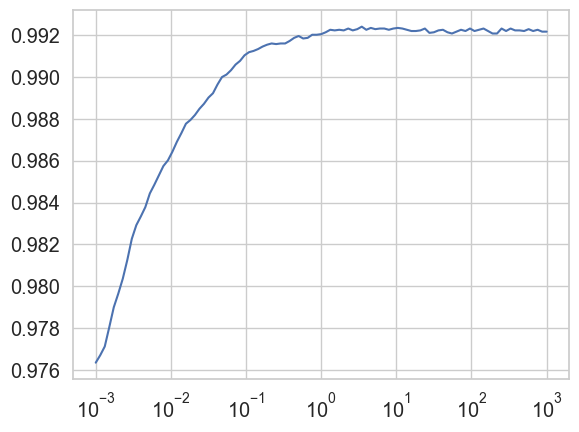

In [24]:
# Regularization strength (5-fold cross-validation)
search = GridSearchCV(LogisticRegression(max_iter=10000), dict(C=np.logspace(-3, 3, 101)), n_jobs=-1, cv=5).fit(X, y)
print(search.best_params_)
plt.plot(search.param_grid["C"], search.cv_results_["mean_test_score"])
plt.xscale("log")

Text(0, 0.5, 'True positive rate')

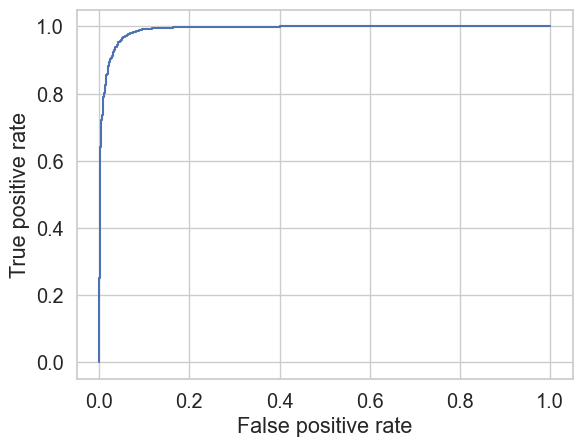

In [25]:
# Model used to flag the directors
clf = LogisticRegression(C=0.1, max_iter=10000).fit(X, y)

fpr, tpr, thresholds = roc_curve(y, clf.predict_proba(X)[:, 0], pos_label=0)
plt.plot(fpr, tpr)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")

In [26]:
# Confidence intervals of the coefficients (bootstrap)
C_CV = search.best_params_["C"]  # cross-validated regularization strength
coefs = []
for i in range(100):
    data2 = data.sample(frac=1, replace=True)
    clf_b = LogisticRegression(C=C_CV, max_iter=10000).fit(data2[vars_fit_log].values, data2["pos"].values)
    coefs.append(clf_b.coef_[0])

boot_coef = pd.DataFrame(coefs, columns=vars_fit_log)
boot_sum = boot_coef.apply(lambda x: np.percentile(x, [2.5, 50, 97.5]))
boot_sum = boot_sum.T.sort_values(by=1)

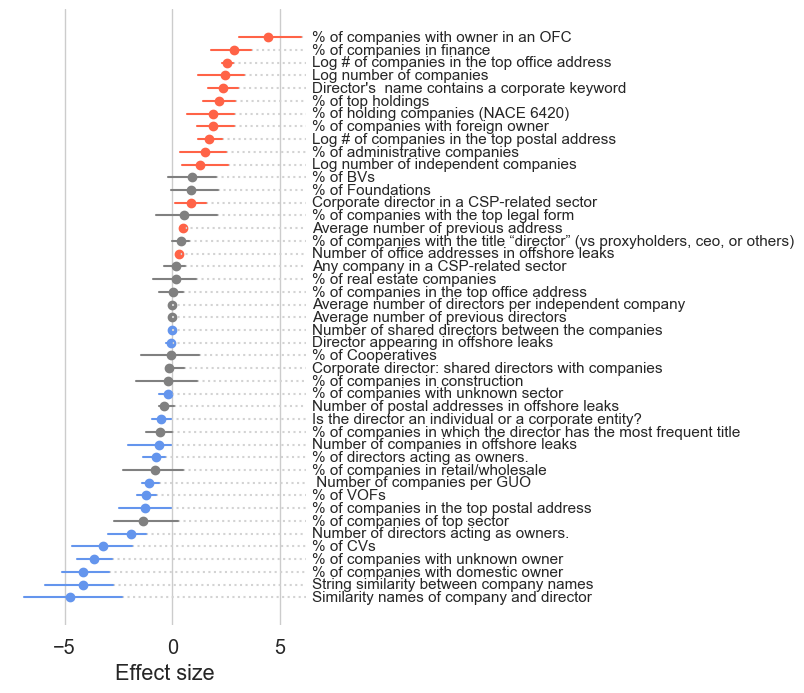

In [27]:
# Effect sizes (Appendix A.10)
x_lab = np.ceil(boot_sum.values.max()) + 0.5  # position of the labels
plt.figure(figsize=(4, 8))
i = 0
for var, row in boot_sum.iterrows():
    i += 1
    if row[2] < 0:
        color = "cornflowerblue"
    elif row[0] > 0:
        color = "tomato"
    else:
        color = "gray"
    plt.plot([row[2], x_lab-0.3], [i, i], ":", color="lightgray")
    plt.plot([row[0], row[2]], [i, i], color=color)
    plt.scatter(row[1], i, color=color)
    plt.annotate(var2eng[var], (x_lab, i), va="center", fontsize=11)

plt.gca().grid(axis='y')
plt.yticks([])
sns.despine(left=True, bottom=True)
plt.xlabel("Effect size")
plt.savefig("Figures/logit.pdf", bbox_inches="tight")

In [28]:
# Flag directors with a probability of being a CSP above 1%
df_cluster["ix_logit"] = clf.predict_proba(df_cluster[vars_fit_log].values)[:, 0] < 0.99

# Overlap between both algorithms (Figure 4C)
pd.crosstab([df_cluster["ix"], df_cluster["ix_logit"]], df_cluster["RTO_confidence"] > 3, margins=True)

RTO_confidence  False  True    All
ix    ix_logit                    
False False     29019     9  29028
      True       3671    14   3685
True  False       810    17    827
      True       2134   869   3003
All             35634   909  36543

In [29]:
# Two random samples of 50 directors flagged by the logistic regression but not by the nearest neighbours
if CREATE_ANNOTATION_SAMPLES:
    for i in [1, 2]:
        sample = df_cluster.loc[(df_cluster["ix_logit"] == True) & (df_cluster["ix"] == False)].sample(n=50)
        save_sample(f"manual_sample_logit_{i}", sample)

## 4. Characteristics of the flagged directors (Section 4.2, Figure 6)

Mean of each (robust-scaled) feature for licensed CSPs, directors flagged by each algorithm, and directors not flagged.

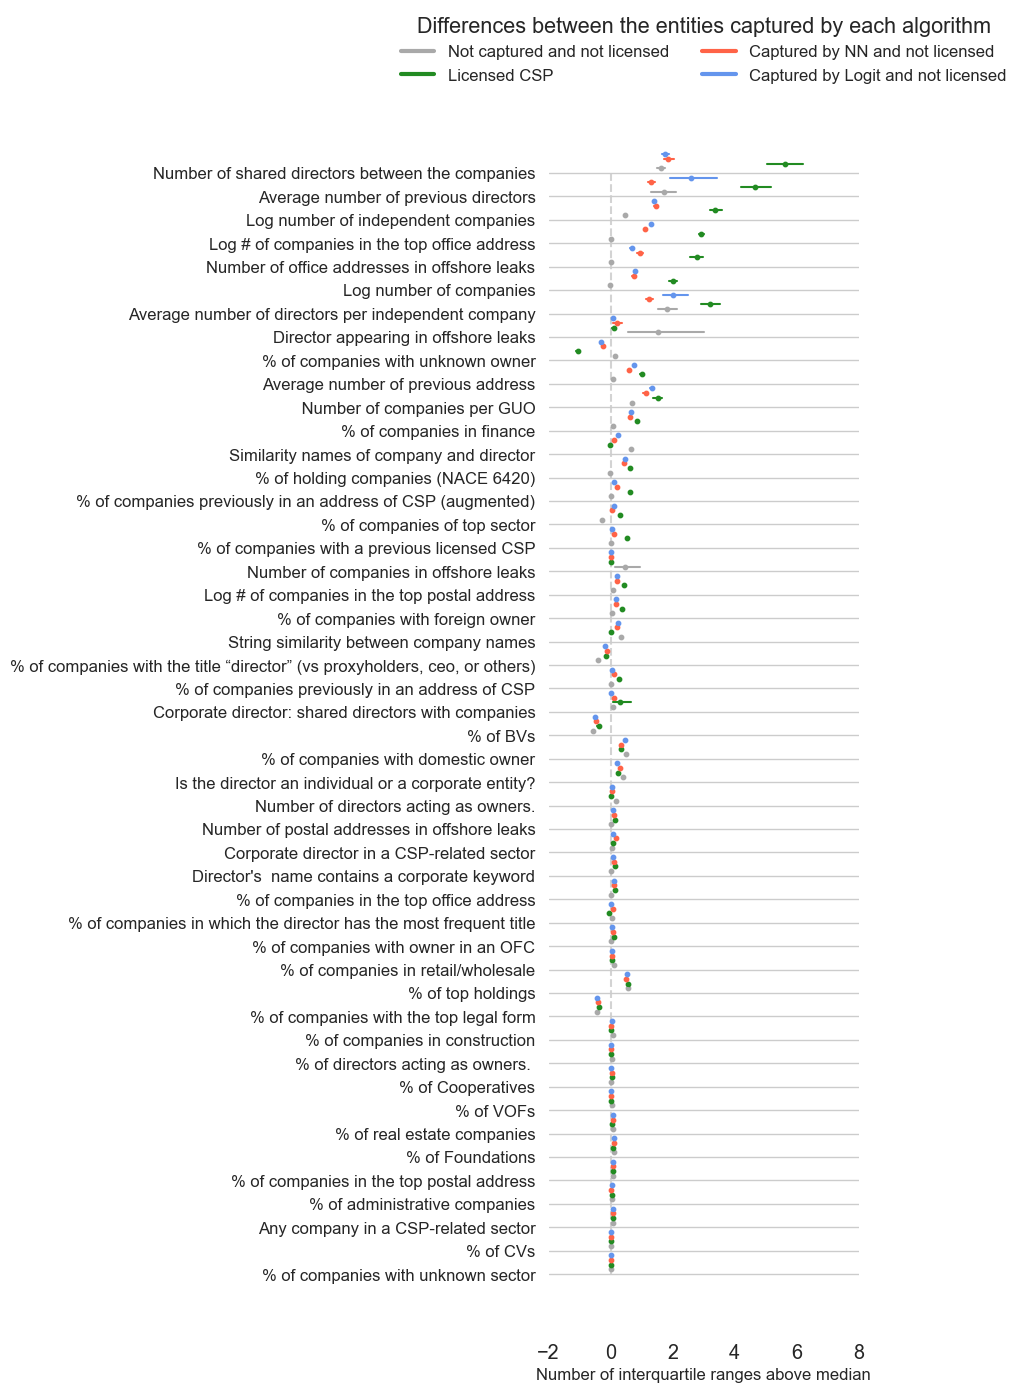

In [30]:
d_labels = {0: "Not captured by NN and licensed CSP", 1: "Not captured and not licensed",
            10: "Licensed CSP", 11: "Captured by NN and not licensed"}
d_labels_color = {0: "darkgray", 1: "darkgray",
                  10: "forestgreen", 11: "tomato"}

df_cluster_fe = df_cluster.copy()
df_cluster_fe["Type"] = df_cluster_fe["ix"]*10+(df_cluster_fe["RTO_confidence"] < 4)
df_cluster_fe.loc[df_cluster_fe["Type"] == 0, "Type"] = 10
df_cluster_fe["Type_logit"] = (df_cluster_fe["ix_logit"]) & (df_cluster_fe["RTO_confidence"] < 4)
# 1 = not captured by any algorithm
df_cluster_fe.loc[(df_cluster_fe["Type_logit"] == 1) & (df_cluster_fe["Type"] == 1), "Type"] = 0

df_cluster_fe[vars_fit] = RobustScaler().fit_transform(df_cluster_fe[vars_fit])

n_mean = df_cluster_fe.groupby("Type")
n_mean_logit = df_cluster_fe.groupby("Type_logit")

# Sort the variables by the differences between groups
top_x = []
for i, var in enumerate(vars_fit):
    if var not in var2eng:
        continue
    mean = n_mean[var].mean()
    top_x.append((np.abs(mean[1]-mean[11])+np.abs(mean[1]-mean[10])+np.abs(mean[10]-mean[11]), var))
_, vars_fit_sorted = zip(*sorted(top_x))

plt.figure(figsize=(4, 16))
for i, var in enumerate(vars_fit_sorted):
    perc = n_mean[var].apply(lambda x: bootstrap_ci(x, statfunction=np.average, alpha=0.05, n_samples=1000))
    mean = n_mean[var].mean()

    perc_logit = n_mean_logit[var].apply(lambda x: bootstrap_ci(x, statfunction=np.average, alpha=0.05, n_samples=1000))
    mean_logit = n_mean_logit[var].mean()

    j = 0
    for index in mean.index:
        if index == 0:
            continue
        j += 0.2
        plt.scatter(mean[index], i+j, color=d_labels_color[index], label="", s=10)
        plt.plot(perc[index], [i+j, i+j], color=d_labels_color[index])
    j += 0.2
    plt.scatter(mean_logit[1], i+j, color="cornflowerblue", label="", s=10)
    plt.plot(perc_logit[1], [i+j, i+j], color="cornflowerblue")

plt.yticks(np.arange(i+1), [var2eng[_] for _ in vars_fit_sorted], fontsize=12)
plt.plot([0, 0], [0, i], "--", color="lightgray", zorder=0)
sns.despine(bottom=True, left=True)
plt.gca().grid(axis="x")
plt.xlim(-2, 8)
plt.xticks(range(-2, 9, 2))
plt.xlabel("Number of interquartile ranges above median", fontsize=12)

for ind in d_labels_color:
    if ind == 0:
        continue
    plt.plot([35, 45], [1, 1], color=d_labels_color[ind], label=d_labels[ind], lw=3)
plt.plot([35, 45], [1, 1], color="cornflowerblue", label="Captured by Logit and not licensed", lw=3)
plt.legend(ncol=2, frameon=False, fontsize=12, title="Differences between the entities captured by each algorithm", loc="lower center", bbox_to_anchor=(0.5, 1.0))
plt.tight_layout()
plt.savefig("Figures/samples_comparison.svg")
plt.show()

## 5. Size of the illegal CSP sector (Section 4.1)

The number of illegal CSPs among the directors flagged by each algorithm follows a binomial distribution. We estimate the true positive rate with a uniform prior (Beta(1,1)), so the posterior is Beta(TP+1, FP+1), and multiply it by the number of directors flagged.

In [31]:
# Results of the manual annotation (non-licensed directors): providing corporate services ("5"), not providing them ("1") or unknown ("3")
nn_labels = annotated["nn"]["trust_services"].value_counts()
logit_labels = pd.concat([annotated["logit_1"], annotated["logit_2"]])["trust_services"].value_counts()
NN_TP, NN_FP, NN_UNK = (int(nn_labels.get(k, 0)) for k in ["5", "1", "3"])
NN_N = NN_TP + NN_FP + NN_UNK
LOGIT_TP, LOGIT_UNK, LOGIT_N = int(logit_labels.get("5", 0)), int(logit_labels.get("3", 0)), int(logit_labels.sum())

# Number of non-licensed directors flagged by the nearest neighbours, and only by the logistic regression
lic = df_cluster["RTO_conf_bool"]
N_NN = int((df_cluster["ix"] & ~lic).sum())
N_LOGIT = int((df_cluster["ix_logit"] & ~df_cluster["ix"] & ~lic).sum())

print(f"Nearest neighbours: {N_NN} directors flagged; annotated {NN_TP} CSPs, {NN_FP} not CSPs, {NN_UNK} unknown")
print(f"Logistic regression: {N_LOGIT} directors flagged; annotated {LOGIT_TP} CSPs, {LOGIT_N-LOGIT_TP-LOGIT_UNK} not CSPs, {LOGIT_UNK} unknown")

Nearest neighbours: 2944 directors flagged; annotated 8 CSPs, 54 not CSPs, 14 unknown
Logistic regression: 3671 directors flagged; annotated 1 CSPs, 88 not CSPs, 10 unknown


In [32]:
def calculate_ci(tp, total, prior="uniform", print_mean=False):
    """95% interval and median of the posterior Beta(tp+1, total+1) of the true positive rate."""
    x = np.linspace(0, 0.5, 1001)
    if prior == "uniform":
        posterior = beta.pdf(x, tp+1, total+1)
    else:  # 1 in 50
        posterior = beta.pdf(x, tp+1, total+20)
    cumsum = np.cumsum(posterior)*0.0005
    v1 = np.nonzero(cumsum > 0.025)[0][0]
    v_m = np.nonzero(cumsum > 0.5)[0][0]
    v2 = np.nonzero(cumsum > 0.975)[0][0]

    if print_mean:
        print("Max", x[posterior == np.max(posterior)])
        print(np.sum(x*posterior*0.0005))
    return (np.array([x[v1], x[v2]]), x[v_m])

Random sample of 1100 directors: [178. 588.] | our approach: [162. 573.]


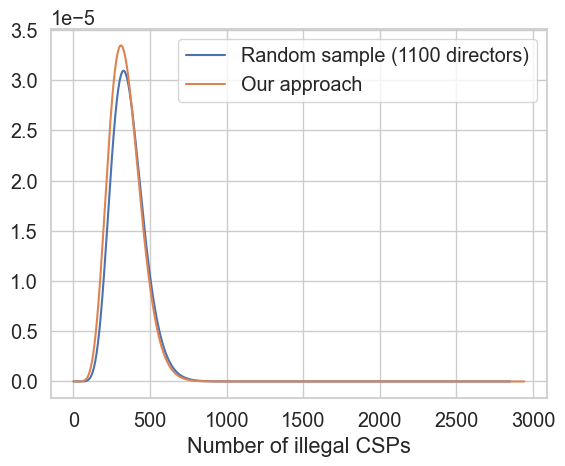

In [33]:
# How large would a random sample of directors need to be to get a similar 95% interval?
ci_ours, tp_nn = calculate_ci(NN_TP, NN_N-NN_TP)
ci_ours *= N_NN
n_illegal = tp_nn*N_NN                      # estimated number of illegal CSPs flagged by the nearest neighbours
n_not_licensed = int((~lic).sum())
for n_random in range(100, 100001, 100):
    ci_random = calculate_ci(n_illegal*n_random/n_not_licensed, n_random)[0]*n_not_licensed
    if ci_random[1]-ci_random[0] <= ci_ours[1]-ci_ours[0]:
        break
print(f"Random sample of {n_random} directors: {np.round(ci_random)} | our approach: {np.round(ci_ours)}")

x = np.linspace(0, 0.08, 1001)
posterior1 = beta.pdf(x, n_illegal*n_random/n_not_licensed+1, n_random+1)
plt.plot(x*n_not_licensed, posterior1/np.sum(posterior1*x*n_not_licensed), label=f"Random sample ({n_random} directors)")
x = np.linspace(0, 1, 1001)
posterior1 = beta.pdf(x, NN_TP+1, NN_N-NN_TP+1)
plt.plot(x*N_NN, posterior1/np.sum(posterior1*x*N_NN), label="Our approach")
plt.xlabel("Number of illegal CSPs")
plt.legend()

Nearest neighbours
TP	(330c)	161–572
Unk	(558c)	334–841
FP	(2056c)
Logistic regression
TP	(61c)	9–200
Unk	(391c)	205–646
FP	(3219c)


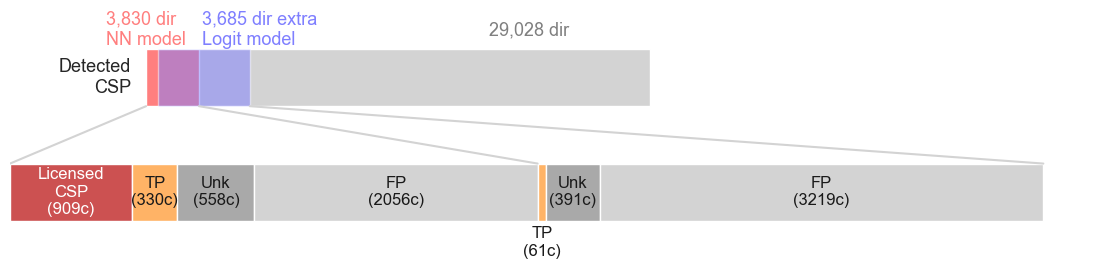

In [34]:
# Figure 4 (draft). Top: directors flagged by each algorithm. Bottom (zoomed in on the flagged directors): licensed CSPs and
# estimated true positives (TP), unknowns (Unk) and false positives (FP) of each algorithm
ix, ix_logit = df_cluster["ix"], df_cluster["ix_logit"]
n_total, n_nn_all, n_nn_only, n_logit_all = len(df_cluster), ix.sum(), (ix & ~ix_logit).sum(), ix_logit.sum()
n_licensed_nn = (ix & lic).sum()

plt.figure(figsize=(14, 3))
plt.barh(0, n_total, color="lightgray", height=0.4)
plt.barh(0, n_nn_all, color="#ff7f7f", height=0.4)
plt.barh(0, n_logit_all, left=n_nn_only, color="#7f7fff", height=0.4, alpha=0.5)
plt.annotate(f"{n_nn_all:,} dir\nNN model", (-0.08*n_total, 0.2), ha="left", va="bottom", color="#ff7f7f", fontsize=13)
plt.annotate(f"{n_nn_only+n_logit_all-n_nn_all:,} dir extra\nLogit model", (0.11*n_total, 0.2), ha="left", va="bottom", color="#7f7fff", fontsize=13)
plt.annotate(f"{n_total-n_nn_only-n_logit_all:,} dir\n", (0.68*n_total, 0.12), ha="left", va="bottom", color="gray", fontsize=13)
plt.annotate("Detected\nCSP", (-0.03*n_total, 0), va="center", ha="right", fontsize=13)

# Bottom bar: zoom on the flagged directors
n_bottom = n_licensed_nn + N_NN + N_LOGIT
scale, offset = 2.05*n_total/n_bottom, -0.27*n_total
z = lambda v: offset + scale*v

def segment(start, width, color, label, text_color="k"):
    plt.barh(-0.8, width*scale, left=z(start), height=0.4, color=color)
    y = -0.8 if width*scale > 0.05*n_total else -1.15  # labels of narrow segments go below the bar
    plt.annotate(label, (z(start+width/2), y), ha="center", va="center", color=text_color, fontsize=12)
    return start + width

end = segment(0, n_licensed_nn, "#CC5151", f"Licensed\nCSP\n({lic.sum()}c)", "white")
for name, n, tp_count, unk_count, n_annotated in [("Nearest neighbours", N_NN, NN_TP, NN_UNK, NN_N),
                                                    ("Logistic regression", N_LOGIT, LOGIT_TP, LOGIT_UNK, LOGIT_N)]:
    tp_ci, tp = calculate_ci(tp_count, n_annotated-tp_count)
    tu_ci, tu = calculate_ci(unk_count, n_annotated-unk_count)
    fp = 1-tp-tu
    print(name)
    print("TP\t({:.0f}c)\t{}–{}".format(tp*n, *np.array(tp_ci*n, dtype=int)))
    print("Unk\t({:.0f}c)\t{}–{}".format(tu*n, *np.array(tu_ci*n, dtype=int)))
    print("FP\t({:.0f}c)".format(fp*n))
    end = segment(end, tp*n, "#ffb366", "TP\n({:.0f}c)".format(tp*n))
    end = segment(end, tu*n, "darkgray", "Unk\n({:.0f}c)".format(tu*n))
    end = segment(end, fp*n, "lightgray", "FP\n({:.0f}c)".format(fp*n))

for top, bottom in [(0, 0), (n_nn_all, n_licensed_nn+N_NN), (n_nn_only+n_logit_all, end)]:
    plt.plot([top, z(bottom)], [-0.2, -0.6], color="lightgray")
plt.ylim(-1.3, 0.31)
plt.axis(False)
plt.savefig("Figures/summ_bayes.pdf", bbox_inches="tight")

Number of illegal CSPs, and of the positions and companies they manage (Figure 5). We take 1,000,000 draws from the posterior of each algorithm and sum them.

In [35]:
df_cluster["guos"] = df_cluster["guos"].apply(literal_eval)
df_cluster["comps"] = df_cluster["comps"].apply(literal_eval)

# 1 = not flagged, 2 = flagged by the nearest neighbours and not licensed, 3 = licensed CSP, 4 = flagged only by the logistic regression and not licensed
df_cluster["cat"] = 1
df_cluster.loc[(df_cluster["ix"] == 1) & (df_cluster["RTO_confidence"] < 4), "cat"] = 2
df_cluster.loc[(df_cluster["ix_logit"] == 1) & (df_cluster["ix"] != 1), "cat"] = 4
df_cluster.loc[df_cluster["RTO_confidence"] >= 4, "cat"] = 3
df_cluster["c"] = 1
sum_c = df_cluster.groupby("cat")[["c", "n_comp", "total_guo", "guos", "comps"]].agg({"c": "sum", "n_comp": "sum", "total_guo": "sum",
                                                                                     "guos": lambda x: len(set([el for sublist in x for el in sublist])),
                                                                                     "comps": lambda x: len(set([el for sublist in x for el in sublist]))})
# Expected values: false positives of the nearest neighbours are not CSPs
sum_c.loc[1] = sum_c.loc[1]+sum_c.loc[2]*(NN_FP/NN_N)
sum_c.loc[2] *= NN_TP/NN_N
sum_c.loc[4] *= LOGIT_TP/LOGIT_N

# Average number of positions (comps_per_tsp_t), independent positions (comps_per_tsp), companies (actual_comps_per_tsp_t)
# and independent companies (actual_comps_per_tsp) per CSP
sum_c["comps_per_tsp"] = sum_c["total_guo"]/sum_c["c"]
sum_c["comps_per_tsp_t"] = sum_c["n_comp"]/sum_c["c"]
sum_c["actual_comps_per_tsp"] = sum_c["guos"]/sum_c["c"]
sum_c["actual_comps_per_tsp_t"] = sum_c["comps"]/sum_c["c"]
display(sum_c)

licensed = df_cluster.loc[df_cluster["RTO_confidence"] > 3, "n_comp"]
print("Companies managed by licensed CSPs: mean", licensed.mean(), "median", licensed.median())

,c,n_comp,total_guo,guos,comps,comps_per_tsp,comps_per_tsp_t,actual_comps_per_tsp,actual_comps_per_tsp_t
cat,,,,,,,,,
1,31110.789474,143577.578947,114648.736842,86067.210526,113101.184211,3.685176,4.615041,2.766475,3.635433
2,309.894737,2463.789474,1711.368421,1254.105263,1858.842105,5.522418,7.950408,4.046875,5.998302
3,909.000000,17917.000000,12547.000000,6913.000000,10168.000000,13.803080,19.710671,7.605061,11.185919
4,37.080808,275.262626,186.515152,137.303030,208.747475,5.029965,7.423318,3.702806,5.629529


Companies managed by licensed CSPs: mean 19.71067106710671 median 10.0


In [36]:
def return_cis(nn_average, logit_average):
    """Median and 95% interval of the number of illegal CSPs, multiplied by the average number of companies per CSP."""
    x = np.linspace(0, 0.5, 1001)
    posterior_nn = beta.pdf(x, NN_TP+1, NN_FP+NN_UNK+1)
    posterior_nn /= np.sum(posterior_nn)
    posterior_logit = beta.pdf(x, LOGIT_TP+1, LOGIT_N-LOGIT_TP+1)
    posterior_logit /= np.sum(posterior_logit)

    draw_nn = np.random.choice(x, 1000000, p=posterior_nn)*N_NN*nn_average
    draw_logit = np.random.choice(x, 1000000, p=posterior_logit)*N_LOGIT*logit_average
    joint = draw_nn+draw_logit
    return np.percentile(joint, [2.5, 50, 97.5])

est_dirs = return_cis(1, 1)
print("Number of illegal CSPs:", np.round(est_dirs))

Number of illegal CSPs: [213. 402. 668.]


Number of positions
[1670. 3163. 5253.]


Number of companies
[1259. 2388. 3967.]


Number of independent companies
[ 847. 1605. 2668.]


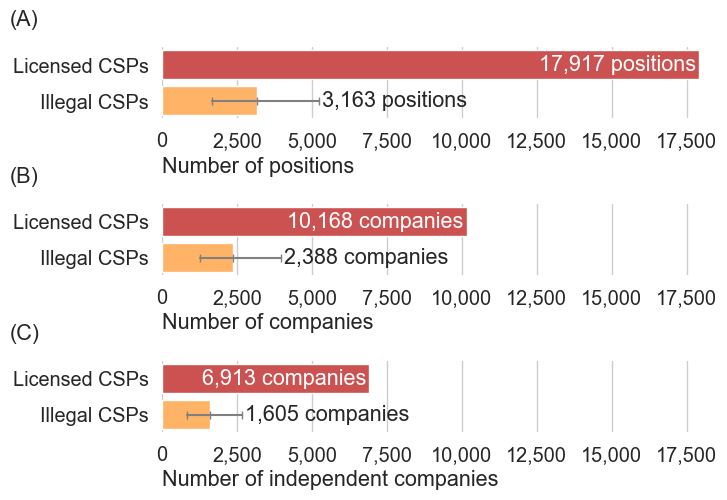

In [37]:
def plot_barplot(sum_c, prefix="", suffix="", ticks=["Licensed CSPs", "Illegal CSPs"], letter="", x_max=None):
    """suffix = "_t" for all companies (instead of independent companies), prefix = "actual_" for companies (instead of positions)."""
    label = "companies" if prefix == "actual_" else "positions"
    label_ind = "" if suffix == "_t" else "independent "

    nn_average = sum_c.loc[2, f"{prefix}comps_per_tsp{suffix}"]
    logit_average = sum_c.loc[4, f"{prefix}comps_per_tsp{suffix}"]
    values = return_cis(nn_average, logit_average)
    print(f"Number of {label_ind}{label}")
    print(np.round(values))
    val_csp = sum_c.loc[3, "c"]*sum_c.loc[3, f"{prefix}comps_per_tsp{suffix}"]

    plt.barh(0, values[1], color="#ffb366")
    plt.barh(1, val_csp, color="#CC5151")
    plt.plot(values, [0, 0, 0], "-|", color="gray")
    sns.despine(bottom=True, left=True)
    plt.grid(axis="y")
    plt.yticks([1, 0], ticks)
    plt.annotate(f"{values[1]:0,.0f} {label} ", (values[-1]+100, 0), va="center", ha="left")
    plt.annotate(f"{val_csp:0,.0f} {label} ", (val_csp+100, 1), va="center", ha="right", color="white")

    plt.xlabel(f"Number of {label_ind}{label}", loc="left")
    plt.gca().xaxis.set_major_formatter(mtick.FuncFormatter(lambda y, _: '{:0,.0f}'.format(y)))
    plt.xlim(0, x_max)
    plt.annotate(letter, (-0.28, 1.3), xycoords="axes fraction", annotation_clip=False)
    return values

# Figure 5
x_max = 1.01*sum_c.loc[3, "n_comp"]  # same scale in all panels
fig = plt.figure(figsize=(7, 5))
plt.subplot(311)
est_positions = plot_barplot(sum_c, prefix="", suffix="_t", letter="(A)", x_max=x_max)
plt.subplot(312)
est_comps = plot_barplot(sum_c, prefix="actual_", suffix="_t", letter="(B)", x_max=x_max)
plt.subplot(313)
est_indep = plot_barplot(sum_c, prefix="actual_", suffix="", letter="(C)", x_max=x_max)
fig.subplots_adjust(hspace=1.2)
plt.savefig("Figures/summ_independent.pdf", bbox_inches="tight")

## 6. Extrapolation to small CSPs (Section 4.3, Figure 7)

Probability of providing corporate services as a function of the number of independent companies managed. We fit a linear model (log-log) for directors managing 3–9 companies and extrapolate it to directors managing one or two companies.

In [38]:
# Number of independent companies managed by each director (all directors, also those with one or two positions)
df_dir_current_full = pd.read_csv("data_final/layers/df_dir_current.csv", sep="\t")
dirs = df_dir_current_full.groupby("dir_id")["guo_id"].agg(lambda x: len(set(x))).value_counts()

# Share of licensed CSPs among directors managing over 30 companies
print(df_cluster.loc[df_cluster["n_comp"] > 30, "RTO_conf_bool"].value_counts(normalize=True))

RTO_conf_bool
False    0.587912
True     0.412088
Name: proportion, dtype: float64


In [39]:
df_cluster["RTO467"] = df_cluster["RTO_confidence"] > 3
sample = df_cluster.groupby("total_guo")[["ix", "RTO467", "total_guo"]].agg({"ix": ["mean", len], "RTO467": "mean", "total_guo": "mean"})
sample.columns = ["NN_mean", "len", "RTO_mean", "total_guo"]
sample = sample.reset_index(drop=True)
sample.index = sample.index+2
for i in range(2):
    sample.loc[i, "len"] = dirs.loc[i+1]
    sample.loc[i, "total_guo"] = i+1
sample = sample.sort_index()

# Licensed CSPs from the DNB list (not augmented)
dir_ids_trust = set(json.load(open("data_final/dir_ids_trust.json", "r+")))
rtos = df_dir_current_full.loc[df_dir_current_full["dir_id"].isin(dir_ids_trust), ['guo_id', 'dir_id']].drop_duplicates()
rtos = rtos.groupby("dir_id").count()["guo_id"].value_counts().reset_index()
rtos.columns = ["total_guo", "RTO_mean_2"]

sample = pd.merge(sample, rtos, how="outer")
sample["RTO_mean_2"] /= sample["len"]

# Directors flagged by the nearest neighbours that are not licensed, times the true positive rate
sample["NN_mean"] -= sample["RTO_mean_2"]
sample["NN_mean"] *= NN_TP/NN_N
sample.loc[sample["NN_mean"] < 1E-4] = np.nan

Missing illegal CSPs (upper bound) [1244.  401.] 1645.0 [1244.  802.] 2046.0
Missing licensed CSPs [675. 374.] 1049.0 [675. 747.] 1422.0
Missing illegal CSPs (lower bound) [528. 292.] 820.0 [528. 584.] 1112.0


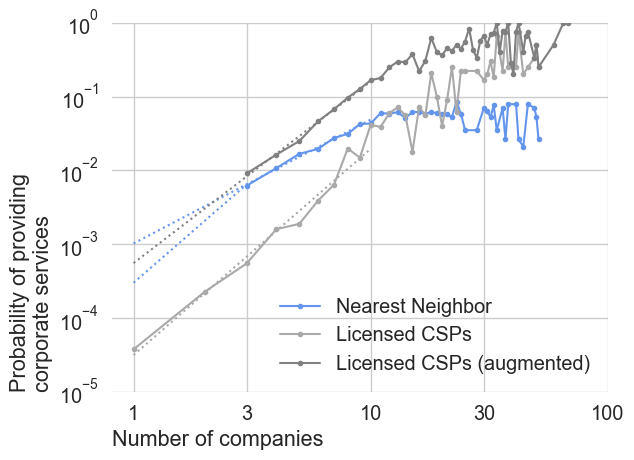

In [40]:
def plot_without_missing(x, y, style, label, color):
    x_plot = x.copy()
    y_plot = y.copy()
    x_plot[y == 0] = np.nan
    y_plot[y == 0] = np.nan
    x_plot = x_plot[np.isfinite(y_plot)]
    y_plot = y_plot[np.isfinite(y_plot)]
    plt.plot(x_plot, y_plot, style, label=label, color=color)

# Number of directors managing one and two independent companies
n_small = dirs.loc[[1, 2]].values

# Nearest neighbours (upper bound)
plot_without_missing(sample["total_guo"], sample["NN_mean"], ".-", label="Nearest Neighbor", color="cornflowerblue")
res = smf.ols(formula='np.log(NN_mean) ~ np.log(total_guo)', data=sample.loc[sample["total_guo"] < 10]).fit()
pred = np.exp(res.predict(sample["total_guo"].head(10)))
mis_dir = pred[:2].values*n_small
mis_comp = pred[:2].values*n_small*[1, 2]
upper_dirs, upper_comps = mis_dir.sum(), mis_comp.sum()
print("Missing illegal CSPs (upper bound)", np.round(mis_dir), np.round(upper_dirs), np.round(mis_comp), np.round(upper_comps))
plt.plot(sample["total_guo"].head(10), pred[:10], ":", color="cornflowerblue")
norm_p = pred[2]

# Licensed CSPs (DNB list), and nearest neighbours extrapolated with their slope
plot_without_missing(sample["total_guo"], sample["RTO_mean_2"], ".-", label="Licensed CSPs", color="darkgray")
res = smf.ols(formula='np.log(RTO_mean_2) ~ np.log(total_guo)', data=sample.loc[sample["total_guo"] < 10]).fit()
pred = np.exp(res.predict(sample["total_guo"].head(10)))
plt.plot(sample["total_guo"].head(10), pred[:10], ":", color="darkgray")
plt.plot(sample["total_guo"].head(3), pred[:3]*norm_p/pred[2], ":", color="cornflowerblue")

# Licensed CSPs (augmented list), and lower bound for the illegal CSPs
plot_without_missing(sample["total_guo"], sample["RTO_mean"], ".-", label="Licensed CSPs (augmented)", color="gray")
res = smf.ols(formula='np.log(RTO_mean) ~ np.log(total_guo)', data=sample.loc[sample["total_guo"] < 10]).fit()
pred = np.exp(res.predict(sample["total_guo"].head(10)))
plt.plot(sample["total_guo"].head(10), pred[:10], ":", color="gray")

mis_dir = pred[:2].values*n_small
mis_comp = pred[:2].values*n_small*[1, 2]
small_licensed_dirs, small_licensed_comps = mis_dir.sum(), mis_comp.sum()
lower_dirs, lower_comps = np.sum(mis_dir*norm_p/pred[2]), np.sum(mis_comp*norm_p/pred[2])
print("Missing licensed CSPs", np.round(mis_dir), np.round(small_licensed_dirs), np.round(mis_comp), np.round(small_licensed_comps))
print("Missing illegal CSPs (lower bound)", np.round(mis_dir*norm_p/pred[2]), np.round(lower_dirs), np.round(mis_comp*norm_p/pred[2]), np.round(lower_comps))

plt.xscale("log")
plt.yscale("log")
plt.legend(frameon=False)
plt.xticks([1, 3, 10, 30, 100], [1, 3, 10, 30, 100])
plt.xlabel("Number of companies", loc="left")
plt.ylabel("Probability of providing \ncorporate services", loc="bottom")
sns.despine(bottom=True, left=True)
plt.ylim(1E-5, 1)
plt.savefig("Figures/extrap.pdf", bbox_inches="tight")

## Market shares (Sections 4.1 and 4.3)

Median and 95% interval of the share of illegal CSPs, and of the positions and companies they manage.

In [41]:
licensed_dirs, licensed_positions, licensed_comps = sum_c.loc[3, ["c", "n_comp", "comps"]]
print("Share of illegal CSPs:", np.round(est_dirs/(est_dirs+licensed_dirs), 3))
print("Share of positions held by illegal CSPs:", np.round(est_positions/(est_positions+licensed_positions), 3))
print("Share of companies managed by illegal CSPs:", np.round(est_comps/(est_comps+licensed_comps), 3))

# Including small CSPs (one or two companies, Figure 7): lower and upper bound
small_illegal_dirs = np.array([lower_dirs, upper_dirs])
small_illegal_comps = np.array([lower_comps, upper_comps])
print("Including small CSPs, share of illegal CSPs:",
      np.round((est_dirs[1]+small_illegal_dirs)/(est_dirs[1]+small_illegal_dirs+licensed_dirs+small_licensed_dirs), 3))
print("Including small CSPs, share of companies:",
      np.round((est_comps[1]+small_illegal_comps)/(est_comps[1]+small_illegal_comps+licensed_comps+small_licensed_comps), 3))

Share of illegal CSPs: [0.19  0.307 0.424]
Share of positions held by illegal CSPs: [0.085 0.15  0.227]
Share of companies managed by illegal CSPs: [0.11  0.19  0.281]
Including small CSPs, share of illegal CSPs: [0.384 0.511]
Including small CSPs, share of companies: [0.232 0.277]
